## Controlando erros no cálculo do PSI via Teorema Central do Limite e método Delta

**Por Estevão Prado e Nicolas Viana**  

Defina $g(p_j, q_j) = (p_j - q_j)\log(p_j/q_j)$ e

$$
\begin{aligned}
\text{PSI}(p,q)
&= \sum_{j=1}^k g(p_j,q_j) \\
&= \sum_{j=1}^k (p_j - q_j)\log\left(\frac{p_j}{q_j}\right) \\
&= \sum_{j=1}^k (p_j - q_j)\left[\log(p_j)-\log(q_j)\right].
\end{aligned}
$$

Na prática, $p=(p_1,\ldots,p_k)$ e $q=(q_1,\ldots,q_k)$ são independentes, uma vez que se tratam de vetores de proporções de períodos diferentes (por exemplo, desenvolvimento e out-of-time).

Usando o Teorema Central do Limite (TCL) e a aproximação da distribuição binomial pela distribuição normal, sabemos que para uma proporção $\widehat{p}_j$ obtida a partir de uma amostra de tamanho $n$,

$$
\widehat{p}_j \sim \mathsf{N}\left(p_j,\frac{p_j(1-p_j)}{n}\right).
$$

Também sabemos (ver p. 243 de Casella & Berger, *Statistical Inference*, 2002) via Método Delta univariado que, se uma sequência de variáveis aleatórias independentes e identicamente distribuídas
$X_1,\ldots,X_n$ satisfaz

$$
\sqrt{n}(\bar X_n-\mu) \xrightarrow{d} \mathsf{N}(0,\sigma^2),
$$

onde $\mathbb{E}(\bar X_n)=\mu$ e $\mathrm{Var}(\bar X_n)=\sigma^2/n$, então para qualquer função derivável $h(\cdot)$ tal que $h'(\mu)\neq 0$,

$$
\sqrt{n}\big[h(X_n)-h(\mu)\big]
\xrightarrow{d}
\mathsf{N}\big(0,\sigma^2[h'(\mu)]^2\big).
$$

A versão multivariada do resultado acima nos ajuda a encontrar a distribuição de $g(p_j,q_j)$. Em particular, fornece uma expressão para a variância de sua distribuição assintótica.

Calculamos abaixo as derivadas parciais de $g(p_j,q_j)$ em relação a $p_j$ e $q_j$:

$$
\frac{\mathsf{d} g(p_j,q_j)}{\mathsf{d} p_j}
\equiv a_j
=
\log\left(\frac{p_j}{q_j}\right) + 1 - \frac{q_j}{p_j},
$$

$$
\frac{\mathsf{d} g(p_j,q_j)}{\mathsf{d} q_j}
\equiv b_j
=
1 - \frac{p_j}{q_j} - \log\left(\frac{p_j}{q_j}\right).
$$

Com isso, a partir do Método Delta multivariado de 1ª ordem e assumindo independência entre $p_j$ e $q_j$, temos que

$$
\widehat{\text{PSI}}
\sim
\mathsf{N}\left(
\text{PSI},
\sum_{j=1}^k \frac{p_j(1-p_j)}{n} a_j^2
+
\sum_{j=1}^k \frac{q_j(1-q_j)}{m} b_j^2
\right).
$$

A partir desse resultado, podemos construir um intervalo de confiança para o PSI:

$$
\text{IC}
=
\widehat{\text{PSI}}
\pm
Z_{1-\alpha/2}
\sqrt{\text{Var}(\widehat{\text{PSI}}^{*})}.
$$

Assumindo $n=m$ e um erro amostral $\epsilon>0$, o tamanho amostral ótimo é dado por

$$
n
=
\frac{
Z_{1-\alpha/2}^2
\left[
\sum_{j=1}^k p_j(1-p_j)a_j^2
+
\sum_{j=1}^k q_j(1-q_j)b_j^2
\right]
}{
\epsilon^2
}.
$$

## Racional por trás da escolha do $n$ ótimo

Na prática, como o PSI é um valor real positivo e diferentes combinações de $p_j$ e $q_j$ podem gerar aproximadamente os mesmos valores, o intervalo de confiança e o tamanho amostral ótimo devem ser calculados levando-se em consideração:

$$
\text{Var}(\widehat{\text{PSI}}^{*}) = \sup_{\widehat{\text{PSI}} \leq c + \epsilon, k=1} \text{Var}(\widehat{\text{PSI}}).
$$

Isso é, para definirmos um $n$ ótimo, precisamos definir um valor de PSI 'alvo', $c$, e selecionar $n$ a partir da combinação de $p_j$ e $q_j$ que apresenta a pior (isto é, a maior) variância para um PSI de aproximadamente $c + \epsilon$.


Para ilustrar o que dissemos acima, assuma $\epsilon = 0.005$, $k = 1$ e $c \equiv \text{PSI} = 0.10$. Como mencionado acima, várias combinações de $p_j$ e $q_j$ podem gerar (aproximadamente) esse valor de $\text{PSI}$. Por exemplo, se i) $p_j = 0.01$ e $q_j = 0.063$ ou ii) $p_j = 0.001$ e $q_j = 0.03$, então $\text{PSI} \approx 0.0975$ e $\text{PSI} \approx 0.0986$, respectivamente. Se iii) $p_j = 0.001$ e $q_j = 0.0315$, então temos que $\text{PSI} \approx 0.105$ e $\text{Var}(\widehat{\text{PSI}}) \approx 1.747$. Para efeitos de comparação, o caso i) apresenta $\text{Var}(\widehat{\text{PSI}}) \approx 0.929$, enquanto o caso ii) possui $\text{Var}(\widehat{\text{PSI}}) \approx 1.604$. Ou seja, embora as combinações i), ii) e iii) apresentem aproximadamente o mesmo valor de PSI, a terceira possui maior variância e $\text{Var}(\widehat{\text{PSI}}^{*}) = 1.747 $. Se assumirmos um nível de confiança de $(1 - \alpha)\%$ (por exemplo, $z_{\alpha/2} = 2.57$, onde $\alpha = 0.01$), o tamanho amostral para estimar o PSI dos casos i), ii) e iii) é de $246.641$, $425.685$ e $463.642$, respectivamente. Note que o tamanho amostral das três combinações tem uma relação direta com suas variâncias.


De maneira mais formal, condicionado ao $\min(p_j, q_j) \geq 0.001$, ao usarmos $\text{Var}(\widehat{\text{PSI}})^*$ para calcular o tamanho amostral 'ótimo' garantimos que para TODOS os valores de $\text{PSI} \leq c$


$$
\mathbb{P}(\text{PSI} \leq c \mid \widehat{\text{PSI}} = c + \epsilon, \text{Var}(\widehat{\text{PSI}})^*) \leq \alpha/2
$$

<!-- $$
\mathbb{P}(\text{PSI} \leq 0.1 \mid \widehat{\text{PSI}} \geq 0.105, \text{Var}(\widehat{\text{PSI}})^*) \leq 0.005
$$ -->

e

$$
\mathbb{P}(\text{PSI} \geq c \mid \widehat{\text{PSI}} = c - \epsilon, \text{Var}(\widehat{\text{PSI}})^*) \leq \alpha/2.
$$

<!-- $$
\mathbb{P}(\text{PSI} \geq 0.1 \mid \widehat{\text{PSI}} \leq 0.095, \text{Var}(\widehat{\text{PSI}})^*) \leq 0.005
$$ -->

## A pior variância se dá quando $k=1$

A seguir, provamos que a maior variância assintótica do PSI, considerando a aproximação via método Delta de 1ª ordem e supondo um valor de PSI fixo, $c$, e um limite inferior $\min(p_j,q_j)\ge \varepsilon>0$, é atingida quando $k=1$. Formalmente, assumindo $0 < p \leq 1$ e $0 < q \leq 1$, queremos

$$
  \sup_{k}\left\{
    \sum_{j=1}^k\left[\frac{p_j(1-p_j)}{n}a_j^2+\frac{q_j(1-q_j)}{m}b_j^2 \right]
    \;\middle|\; 
    \sum_{j=1}^k g(p_j,q_j)=c,\;p_j,q_j\ge\varepsilon
  \right\}.
$$

Primeiramente, provamos que a variância do PSI é uma função convexa e depois apresentamos o resultado principal.

**Lema 1.** Para $q_j\in[\varepsilon,1-\varepsilon]$ fixo, defina
$$
V(\delta) = p(1-p)a(\delta)^{2} + q(1-q)b(\delta)^{2},
$$
$$
a(\delta) = \delta + 1 - e^{-\delta},
$$
$$
b(\delta) = 1 - e^{\delta} - \delta,
$$
sendo $\delta = \log\frac{p}{q}$ e $p = q e^\delta$. Então, $V(\delta)$ é uma função positiva estritamente convexa em $|\delta|$, com valor mínimo em $\delta = 0$.

*Prova.*

Note que $V(\delta) = V(-\delta)$, $a(\delta) = b(-\delta)$ e $b(\delta) = a(-\delta)$. Além disso, para $\delta > 0$, tanto $a(\delta)$ quanto $-b(\delta)$ são funções estritamente crescentes a medida que $\delta$ aumenta. Por outro, para $\delta < 0$, ambas $-a(\delta)$ e $b(\delta)$ são funções estritamente crescentes a medida que $\delta$ diminui. Ou seja, $|a(\delta)|$ e $|b(\delta)|$ são funções estritamente crescentes a medida que $|\delta|$ aumenta. Considerando isso e o fato de que os coeficientes $p(1-p)$ and $q(1-q)$ são positivos, $V(\delta)$ é uma função positiva estritamente convexa em $|\delta|$.

Usando expansão de Taylor em torno de zero, temos que
$$
a(\delta) = 2\delta + O(\delta^{2}),
$$ 
$$
b(\delta) = -2\delta + O(\delta^{2}),
$$
$$
p = q(1+\delta+O(\delta^{2})).
$$

Substituindo essas quantidades em $V$ e assumindo que $\delta \rightarrow 0$,
$$
\begin{aligned}
V(\delta) & = p(1-p)a(\delta)^{2} + q(1-q)b(\delta)^{2} \\
& = 4q(1-q)\delta^{2} + 4q(1-q)\delta^{2} + O(\delta^{3}) \\
& = C(q) \delta^{2} + O(\delta^{3}),
\end{aligned}
$$
sendo $C(q) = 8q(1-q) > 0$. Esse resultado mostra que $V(\delta)$ tem comportamento quadrático próximo a $\delta = 0$. 

Finalmente,
$$
V'(\delta) := \frac{\mathsf{d} V(\delta)}{\mathsf{d}\delta} = (p - 2p^{2}) a^{2} + 2p(1-p) aa' + 2q(1-q)bb',
$$
$$
V''(\delta) := \frac{\mathsf{d^{2}} V(\delta)}{\mathsf{d}\delta^{2}} = (p - 4p^{2})a^{2} + 4(p-2p^{2})aa' + 2p(1-p)[(a')^{2} + aa''] + 2q(1-q)[(b')^{2} + bb''],
$$
onde
$$
a'(\delta) = 1+e^{-\delta}, \quad a''(\delta) = -e^{-\delta},
$$
$$
b'(\delta) = -e^{-\delta}-1, \quad b''(\delta) = -e^{\delta}.
$$
Note que $V'(0) = 0$, $V''(0) = C(q) > 0$ e $V''(\delta) > 0$ para todo $\delta \neq 0$ e $q \in [\epsilon, 1-\epsilon]$. Isso mostra que $\delta = 0$ (i.e., $p = q$) é o mínimo global de $V(\delta)$, uma vez que $V(\delta) \geq 0$ é uma função estritamente convexa. $\text{ } \square$

**Teorema 1.** Seja $c>0$ e $\varepsilon>0$. Assumindo $0 < p_j \leq 1$ e $0 < q_j \leq 1$, entre todos os pares $(p,q)$ tais que 
$$
\sum_{j=1}^k g(p_j,q_j)=c,
\qquad
\min(p_j,q_j)\ge\varepsilon,
$$
a variância do $\widehat{\text{PSI}}$, considerando a aproximação de primeira ordem via método Delta e $m$, $n > 0$,
$$
\text{Var} \left( \widehat{\text{PSI}} \right) = \sum_{j=1}^k \frac{p_j(1-p_j)}{n} a_j^2 + \sum_{j=1}^k \frac{q_j(1-q_j)}{m} b_j^2,
$$
é maximizada quando $k = 1$ com $p_1 \neq q_1$.

*Prova.*

Se, para algum $j$, $p_j=q_j$, então $g(p_j,q_j)=0$ e $a_j=b_j=0$, de modo que a faixa $j$ não contribui nem para o PSI nem para a variância. Qualquer maximização utiliza apenas faixas com $p_j\neq q_j$.

Defina
$$
r_j := \frac{p_j}{q_j},
\qquad
\delta_j := \log r_j.
$$

Então,
$$
g(p_j, q_j) \equiv g(\delta_j) = q_j(e^{\delta_j}-1)\delta_j,
$$
$$
a_j = \delta_j + 1 - e^{-\delta_j},
\qquad
b_j = 1 - e^{\delta_j} - \delta_j.
$$

Para $q_j$ fixo, tanto $g$ quanto $a_j^2$ e $b_j^2$ são funções de $\delta_j$.

Defina a contribuição da variância por faixa como
$$
V(\delta_j) = p_j(1-p)a_j^{2} + q_j(1-q)b_j^{2}, \quad p_j = q_j e^{\delta}.
$$

Pelo Lema 1, $V(\cdot)$ é estritamente convexa e crescente em $|\delta|$ para $\delta \ne 0$. De forma análoga, $g(\cdot)$ é estritamente convexa, crescente para $\delta > 0$ e satisfaz $g(0) = 0$.

Defina $\phi(x) = V(g^{-1}(x))$, $x \ge 0$. Como $g$ é estritamente convexa e crescente com $g(0)=0$, sua inversa $g^{-1}$ é crescente e côncava. Como $V$ é convexa e crescente em $|\delta|$, segue que a composição $\phi = V \circ g^{-1}$ é convexa em $[0,\infty)$ e satisfaz $\phi(0)=0$. Portanto, $\phi$ é superaditiva, isto é,
$$
\phi(x+y) \ge \phi(x) + \phi(y), \qquad x,y \ge 0.
$$
Considere $\delta_{j_1}$ e $\delta_{j_2}$ arbitrários, tal que $g(\tilde\delta) \equiv c = g(\delta_{j_1}) + g(\delta_{j_2})$. Aplicando com $x=g(\delta_{j_1})$ e $y=g(\delta_{j_2})$, obtemos
$$
V(\tilde\delta) = \phi(x+y) \ge \phi(x) + \phi(y) = V(\delta_{j_1}) + V(\delta_{j_2}),
$$
com igualdade apenas se $x=0$ ou $y=0$, isto é, se $\delta_{j_1}=0$ ou $\delta_{j_2}=0$. $\text{ } \square$

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plotnine import *
import scipy.stats as stats
import matplotlib.pyplot as plt

In [86]:
p = 0.001
epsilon = 0.005
psi_alvo = 0.1 + epsilon
q = np.random.rand()  # q inicial

def f(p, q):
    r = p/q
    return np.abs(psi_alvo - q*(r-1)*np.log(r))

def f_grad(p, q):
    return 1 - p/q - np.log(p/q)

# Como não é possível isolar q da função do PSI, fazemos uma aproximação usando o método de Newton-Raphson
while(True):
    q_ant = q
    q = q - f(p, q)/f_grad(p, q)
    if np.abs(q_ant - q) < 0.000001:
        print('q = ' + str(q))
        break

psi_obs = (p-q)*np.log(p/q)
print(psi_obs)


q = 0.031449151146468894
0.10500000000001798


In [78]:
print(p/0.0303121899795229) # psi = 0.10
print(0.0303121899795229/p) # psi = 0.10

0.03299002812649103
30.3121899795229


In [79]:
print(p/0.018224835902121865) # psi = 0.05
print(0.018224835902121865/p) # psi = 0.05

0.05487017855033597
18.224835902121864


In [87]:
# 0.01   0.063   0.9293358885775563   0.09754913057006681
# 0.001  0.03    1.6039644318039539   0.0986347240682025
# 0.001  0.0315  1.7469865107         0.105224620148

# prob_vec = [0.001, 0.0315, 0.01]
prob_vec = [p, q, 1-np.sum([p, q])]  # 1.016254479459  0.105675900346 suposição ######################## esse cara aqui

p_j_sim = prob_vec[0]
q_j_sim = prob_vec[1]

r_j_sim = np.log(p_j_sim / q_j_sim)
a_j_sim = r_j_sim + 1 - q_j_sim/p_j_sim
b_j_sim = 1 - r_j_sim - p_j_sim/q_j_sim

alpha = 0.01  # 99% de confiança
z = stats.norm.ppf(1 - alpha/2)
erro = 0.005  # 5 unidades na terceira casa decimal

n = int((z**2 * (p_j_sim*(1-p_j_sim)*a_j_sim**2 + q_j_sim*(1-q_j_sim) * b_j_sim**2)) / erro**2)
print(n)


462333


In [88]:
def simula_psi_j(n, n_sim = 10000, prob_vec = None):

    # Simulate values from a multinomial distribution with equal probabilities for the outcomes
    sim_a = np.random.multinomial(n, prob_vec, size=n_sim)/n

    ln_p_j = np.log(sim_a[:, 0])
    p_j = sim_a[:, 0]
    q_j = sim_a[:, 1]
    psi_j = (p_j - q_j) * np.log(p_j / q_j)

    return p_j, q_j, psi_j, ln_p_j


n_sim = 50000  # número de simulações
prob_vec = [p, q, 0.001]
m = n

p_j_hat, q_j_hat, psi_j_hat, ln_p_j_hat = simula_psi_j(n=n, n_sim=n_sim, prob_vec=prob_vec)

p_j = prob_vec[0]
q_j = prob_vec[1]

mux = p_j - q_j
muy = np.log(p_j) - np.log(q_j)
psi_j_true = mux * muy

r_j = np.log(p_j / q_j)
a_j = r_j + 1 - q_j/p_j
b_j = 1 - r_j - p_j/q_j

huu = 1/p_j + q_j / p_j**2
hvv = 1/q_j + p_j / q_j**2
huv = -(1/p_j + 1/q_j)

sigma2p = p_j*(1-p_j)/n
sigma2q = q_j*(1-q_j)/m

std_psi_j_true_ordem1 = np.sqrt((p_j * (1 - p_j)) / n * a_j**2 + (q_j * (1 - q_j)) / m * b_j**2)  # binomial
# std_psi_j_true_ordem1 = np.sqrt(1/n * (p_j * a_j**2 - (p_j * a_j)**2) + 1/m * (q_j * b_j**2 - (q_j * b_j)**2))  # multinomial

correcao_ordem2 = 1/2 * (huu**2 * sigma2p**2 + hvv**2 * sigma2q**2 + 2*huv*huv * sigma2p * sigma2q)  # binomial

std_psi_j_true = std_psi_j_true_ordem1  # + correcao_ordem2

df_psi = psi_j_hat

min_psi = min(df_psi)
max_psi = max(df_psi)
mean_psi = np.mean(df_psi)
std_psi = np.std(df_psi)

print('PSI verdadeiro: ' + str(psi_j_true))
print('Desvio padrao do PSI (aprox): '+ str(std_psi_j_true))
print('Desvio padrao do PSI (empirico): ' + str(std_psi))

PSI verdadeiro: 0.10500000000001797
Desvio padrao do PSI (aprox): 0.0019411231283150596
Desvio padrao do PSI (empirico): 0.0019460324563216776


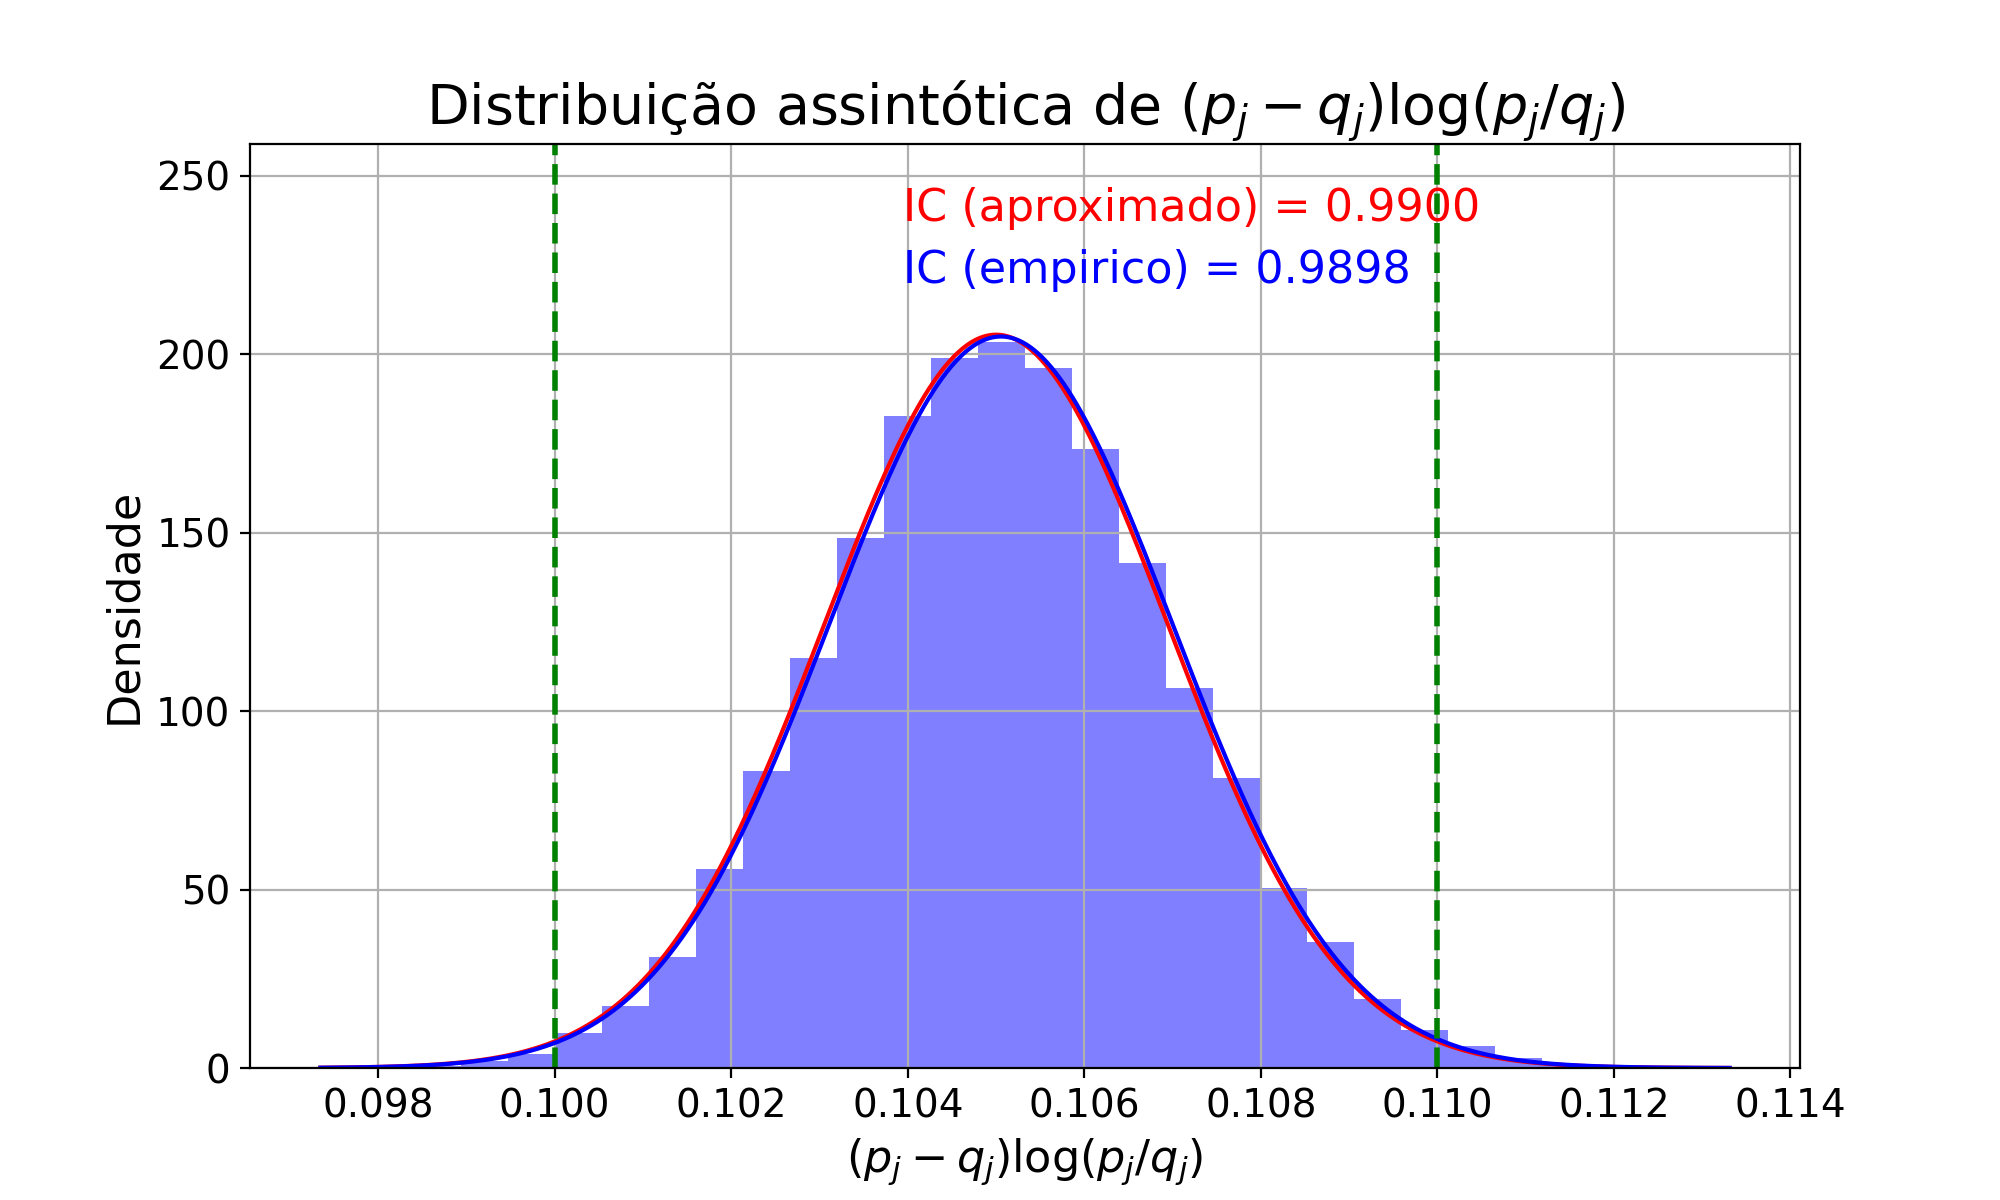

In [51]:
plt.figure(figsize=(10, 6))
# plt.style.use('ggplot')
plt.hist(df_psi, bins=30, density=True, color='blue', alpha=0.5)

x = np.linspace(min_psi, max_psi, 1000)

plt.plot(x, stats.norm.pdf(x, loc=psi_j_true, scale=std_psi_j_true), color='red')
plt.plot(x, stats.norm.pdf(x, loc=mean_psi, scale=std_psi), color='blue')

plt.axvline(psi_j_true - epsilon, color='green', linestyle='--', linewidth=2)
plt.axvline(psi_j_true + epsilon, color='green', linestyle='--', linewidth=2)

plt.title(r'Distribuição assintótica de $(p_j - q_j)\log(p_j / q_j)$', fontsize=20)

prob_interval = stats.norm.cdf(x=psi_j_true+epsilon, loc=psi_j_true, scale=std_psi_j_true) - stats.norm.cdf(x=psi_j_true-epsilon, loc=psi_j_true, scale=std_psi_j_true)
prob_interval_hat = stats.norm.cdf(x=psi_j_true+epsilon, loc=mean_psi, scale=std_psi) - stats.norm.cdf(x=psi_j_true-epsilon, loc=mean_psi, scale=std_psi)

ylim = plt.ylim()
plt.ylim(ylim[0], ylim[1]*1.2)

plt.text(psi_j_true*0.99, ylim[1]*1.1, f'IC (aproximado) = {prob_interval:.4f}', color='red', fontsize=16, ha='left')
plt.text(psi_j_true*0.99, ylim[1]*1.02, f'IC (empirico) = {prob_interval_hat:.4f}', color='blue', fontsize=16, ha='left')

plt.xlabel(r'$(p_j - q_j)\log(p_j / q_j)$', fontsize=16)
plt.ylabel('Densidade', fontsize=16)

plt.grid(True)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.show()

## Verificar a distribuição assintótica $(p_j - q_j) \times \log(p_j / q_j)$ para algumas combinações de $p_j$ e $q_j$ 

# Experimento 1

In [90]:
def fx_j(p, q, m=1, n=1):

    r_j = np.log(p / q)
    a_j = r_j + 1 - q/p
    b_j = 1 - r_j - p/q

    var_xy = (p * (1 - p) / n) * a_j**2 + (q * (1 - q) / m) * b_j**2  # binomial

    return np.round(var_xy, 12)


def psi_j(p, q):
    return np.round((p - q) * np.log(p / q), 12)


# seq_p = np.arange(0, 1, 0.0005)
# seq_q = np.arange(0, 1, 0.0005)
seq_p = np.arange(0, 1, 0.001)
seq_q = np.arange(0, 1, 0.001)

p_grid, q_grid = np.meshgrid(seq_p, seq_q)
p_flat = p_grid.flatten()
q_flat = q_grid.flatten()

var = np.array([fx_j(p, q) for p, q in zip(p_flat, q_flat)])
psi = np.array([psi_j(p, q) for p, q in zip(p_flat, q_flat)])

seq_f = pd.DataFrame({'p': p_flat, 'q': q_flat, 'var': var, 'psi': psi})
print(len(seq_f))

seq_f = seq_f.sort_values('p').drop_duplicates('var')
print(len(seq_f))


/var/folders/6n/__06gfp1733g10g9hdjh6nrc0000gn/T/ipykernel_38998/423995499.py:3: RuntimeWarning: invalid value encountered in scalar divide
/var/folders/6n/__06gfp1733g10g9hdjh6nrc0000gn/T/ipykernel_38998/423995499.py:4: RuntimeWarning: invalid value encountered in scalar divide
/var/folders/6n/__06gfp1733g10g9hdjh6nrc0000gn/T/ipykernel_38998/423995499.py:5: RuntimeWarning: invalid value encountered in scalar divide
/var/folders/6n/__06gfp1733g10g9hdjh6nrc0000gn/T/ipykernel_38998/423995499.py:3: RuntimeWarning: divide by zero encountered in scalar divide
/var/folders/6n/__06gfp1733g10g9hdjh6nrc0000gn/T/ipykernel_38998/423995499.py:5: RuntimeWarning: divide by zero encountered in scalar divide
/var/folders/6n/__06gfp1733g10g9hdjh6nrc0000gn/T/ipykernel_38998/423995499.py:7: RuntimeWarning: invalid value encountered in scalar multiply
/var/folders/6n/__06gfp1733g10g9hdjh6nrc0000gn/T/ipykernel_38998/423995499.py:3: RuntimeWarning: divide by zero encountered in log
/var/folders/6n/__06gfp17

1000000
498527


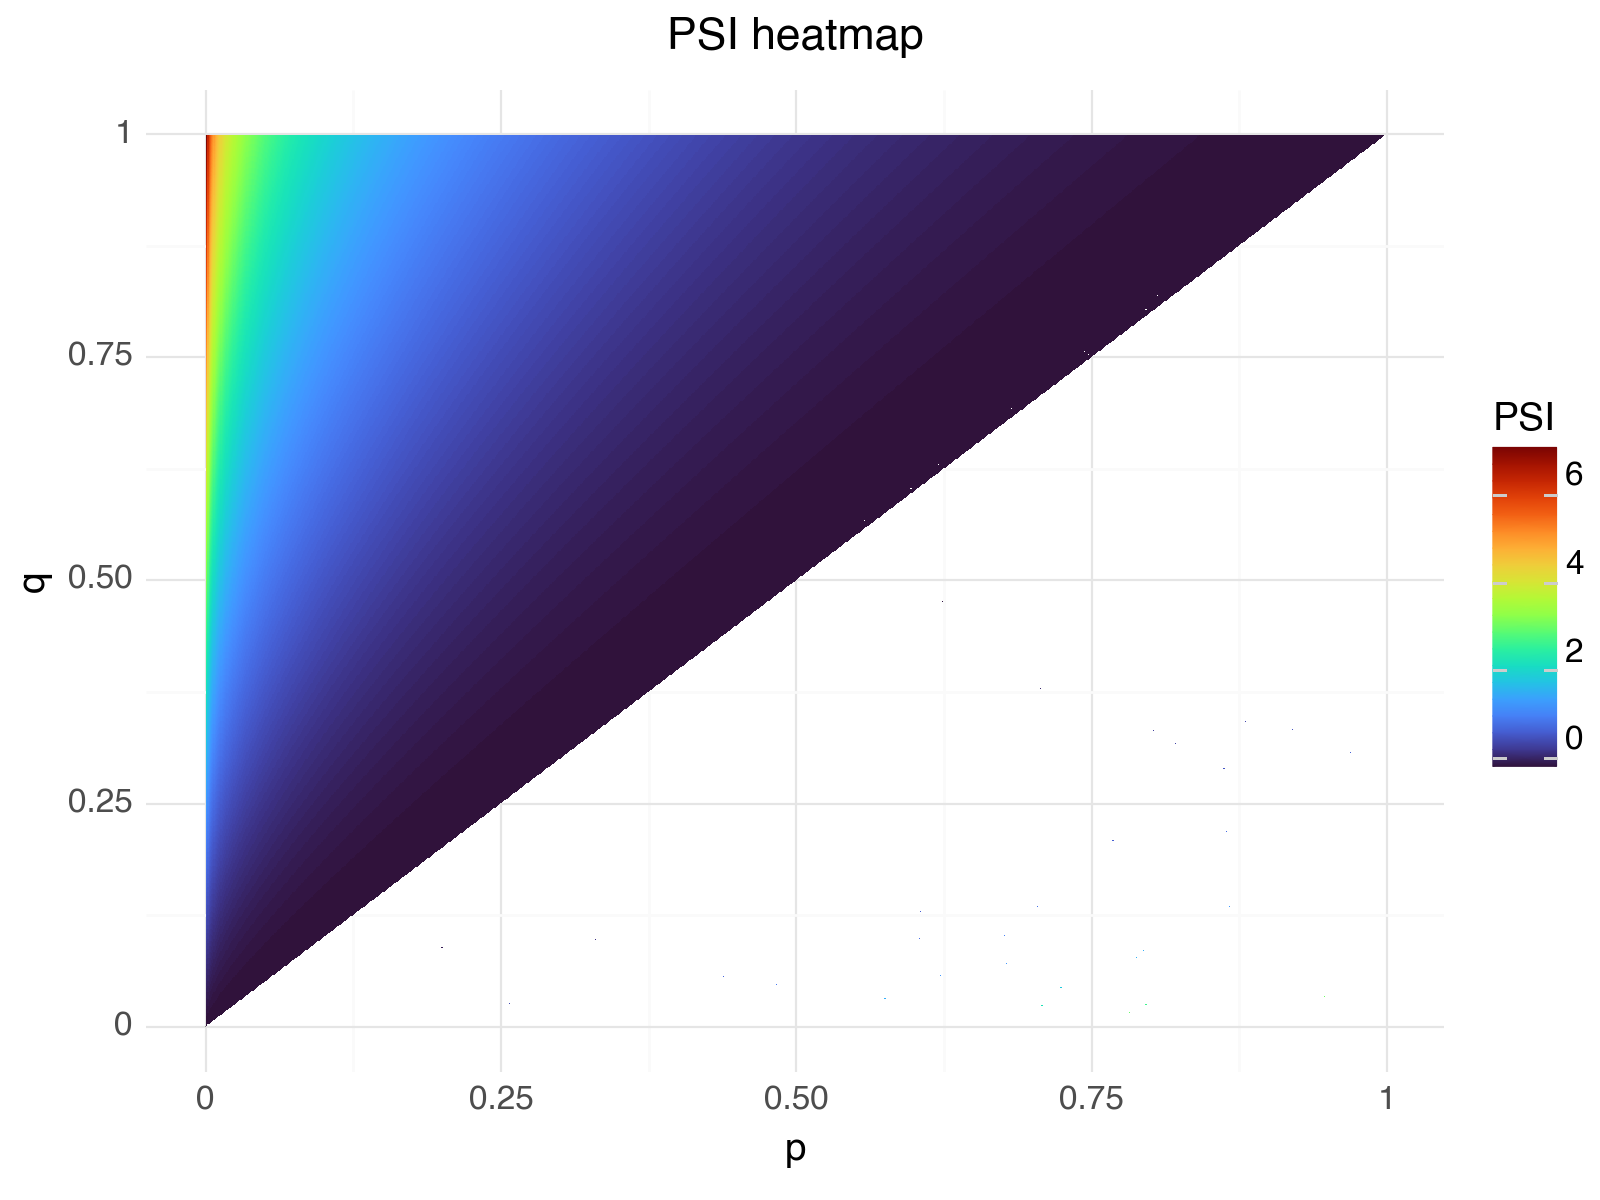

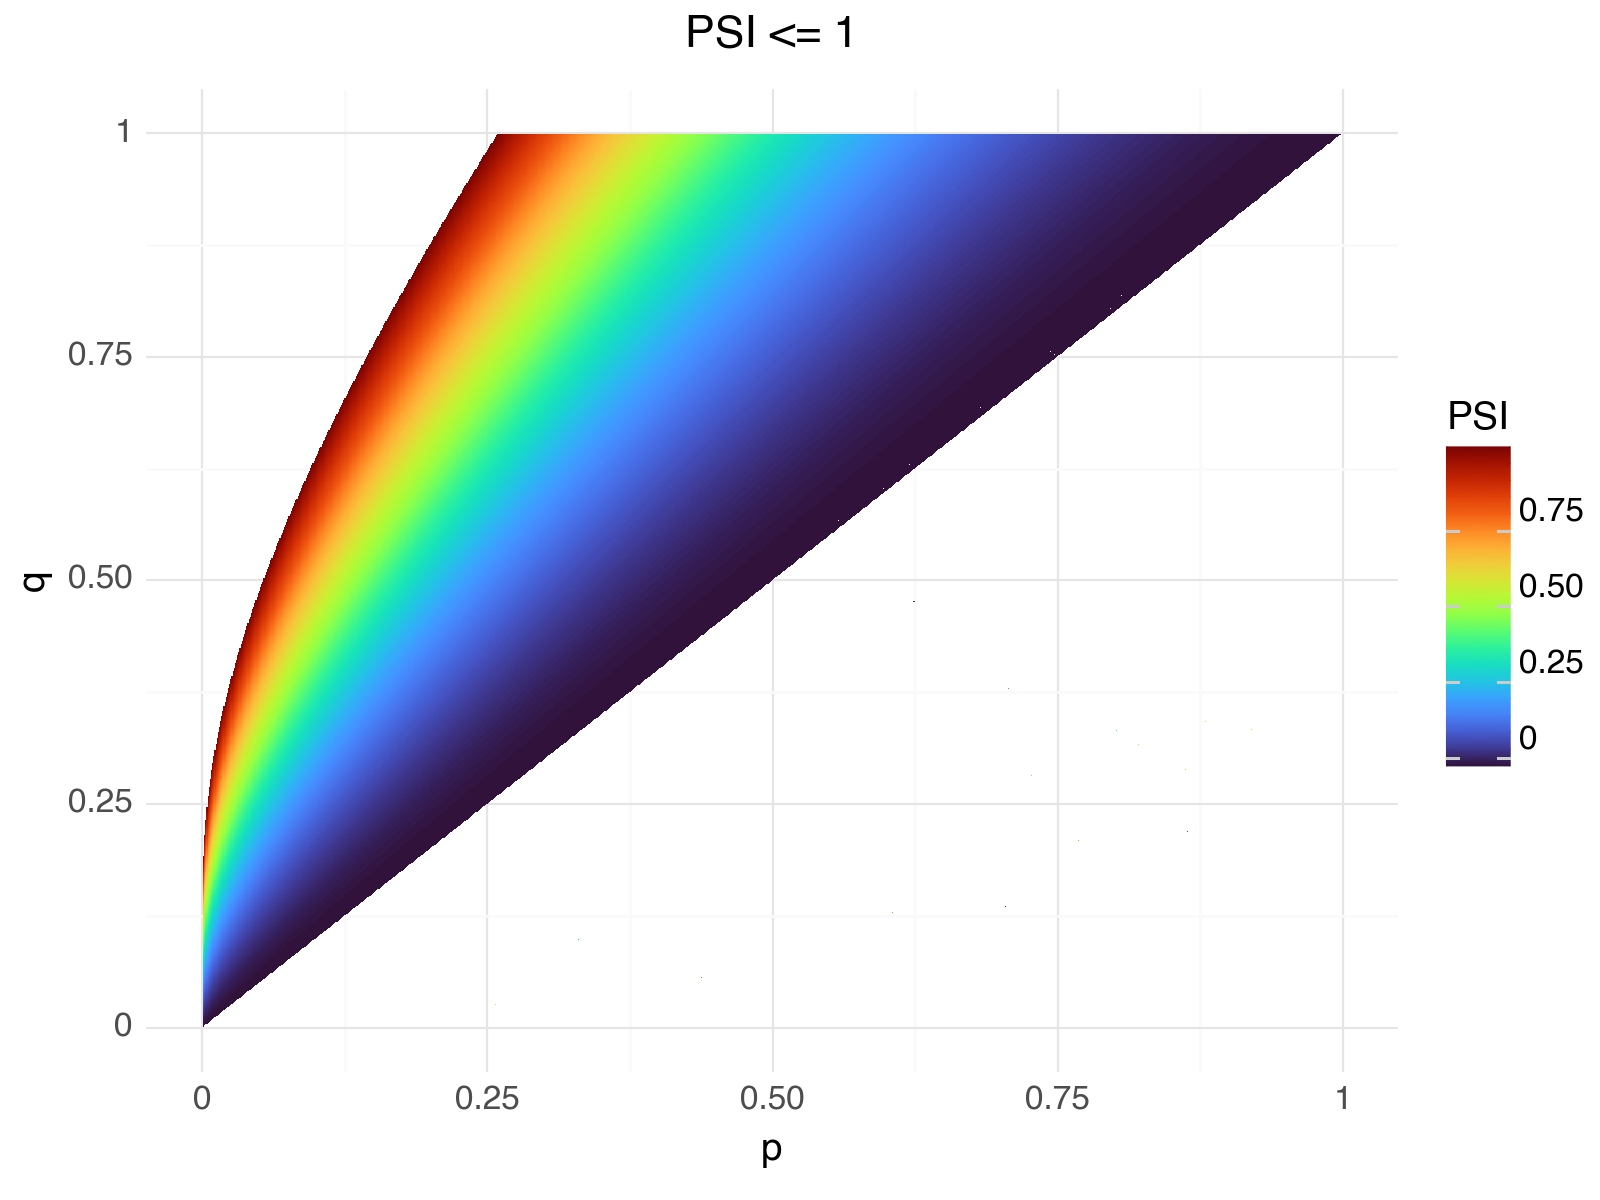

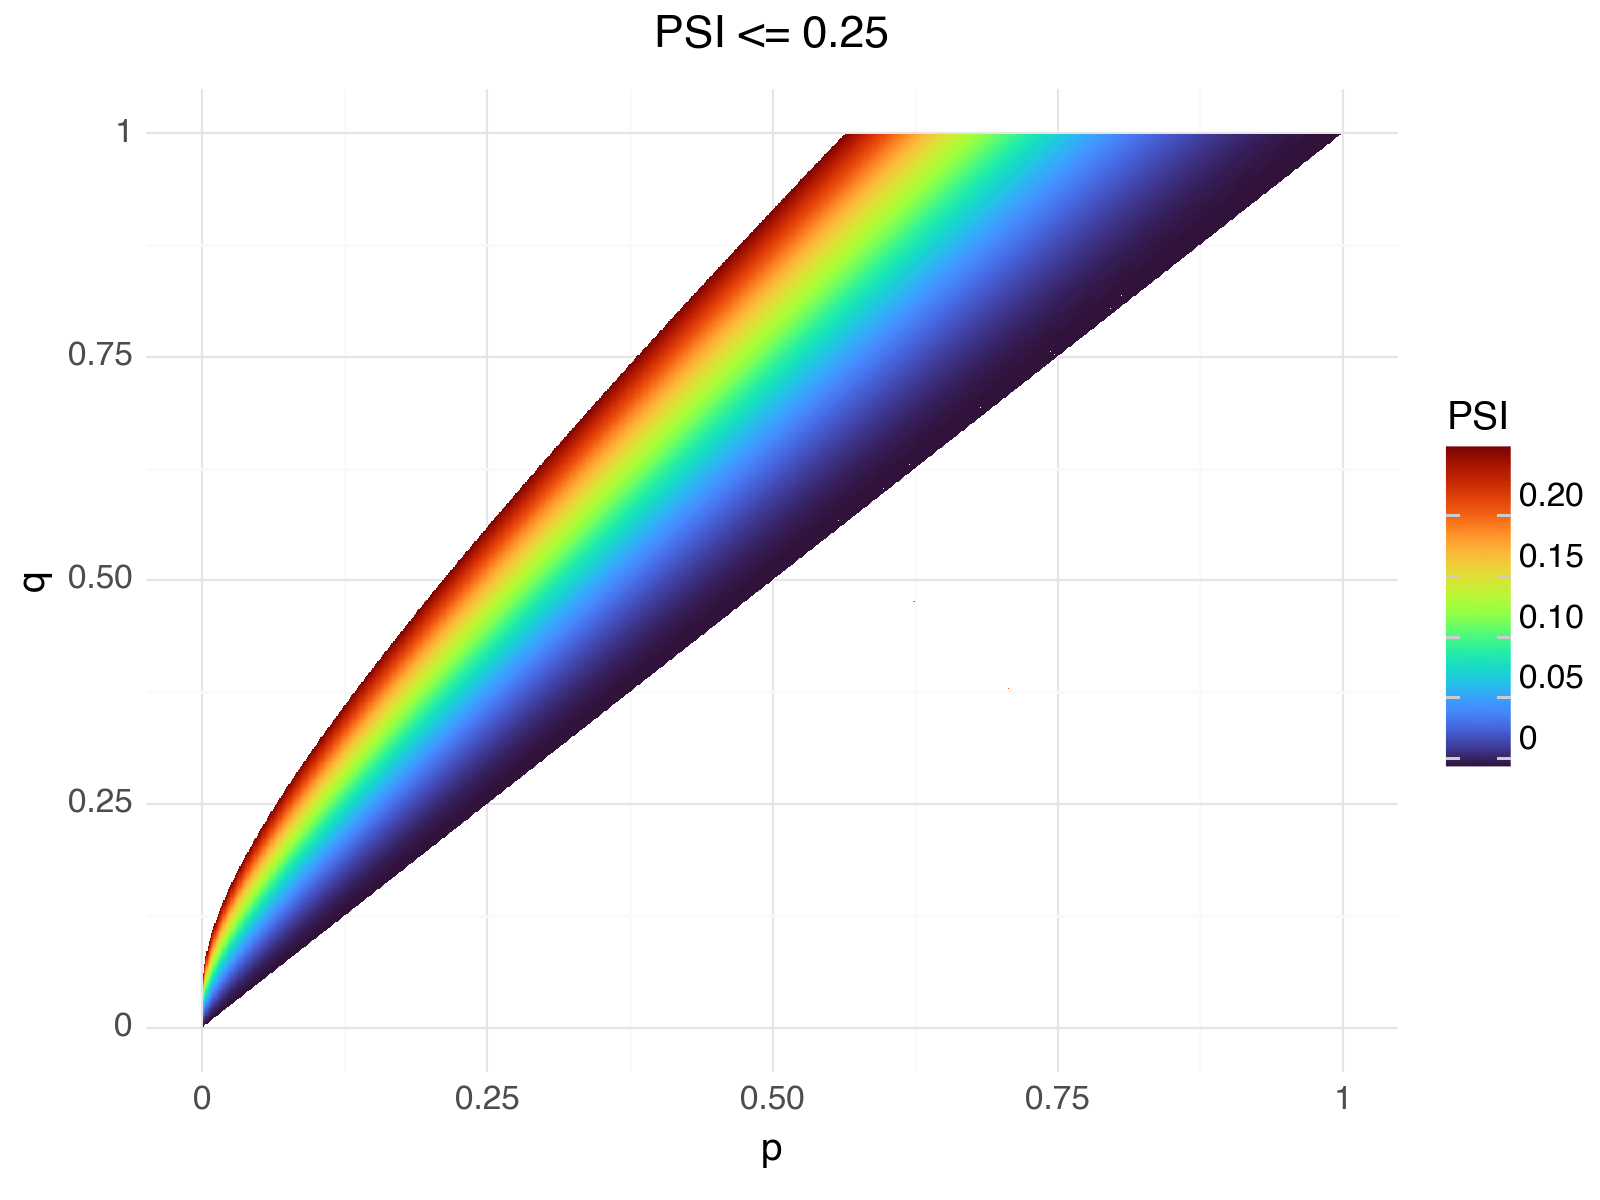

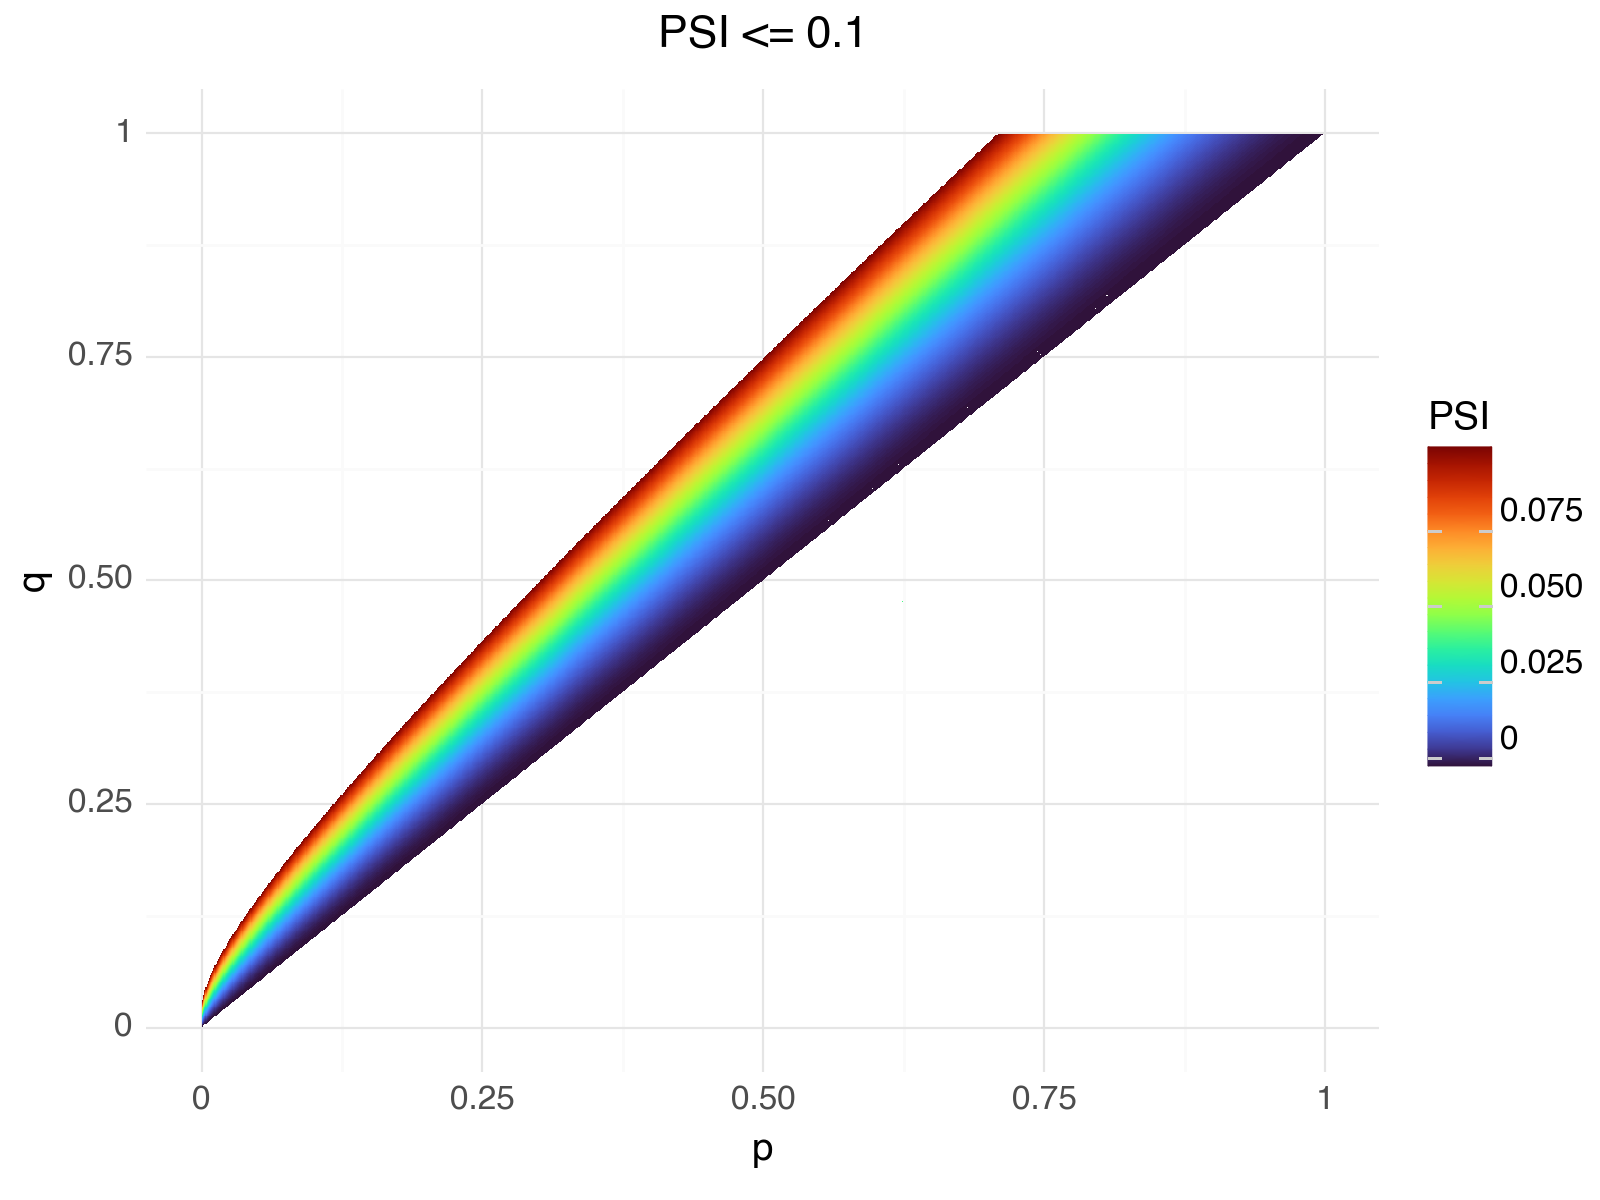

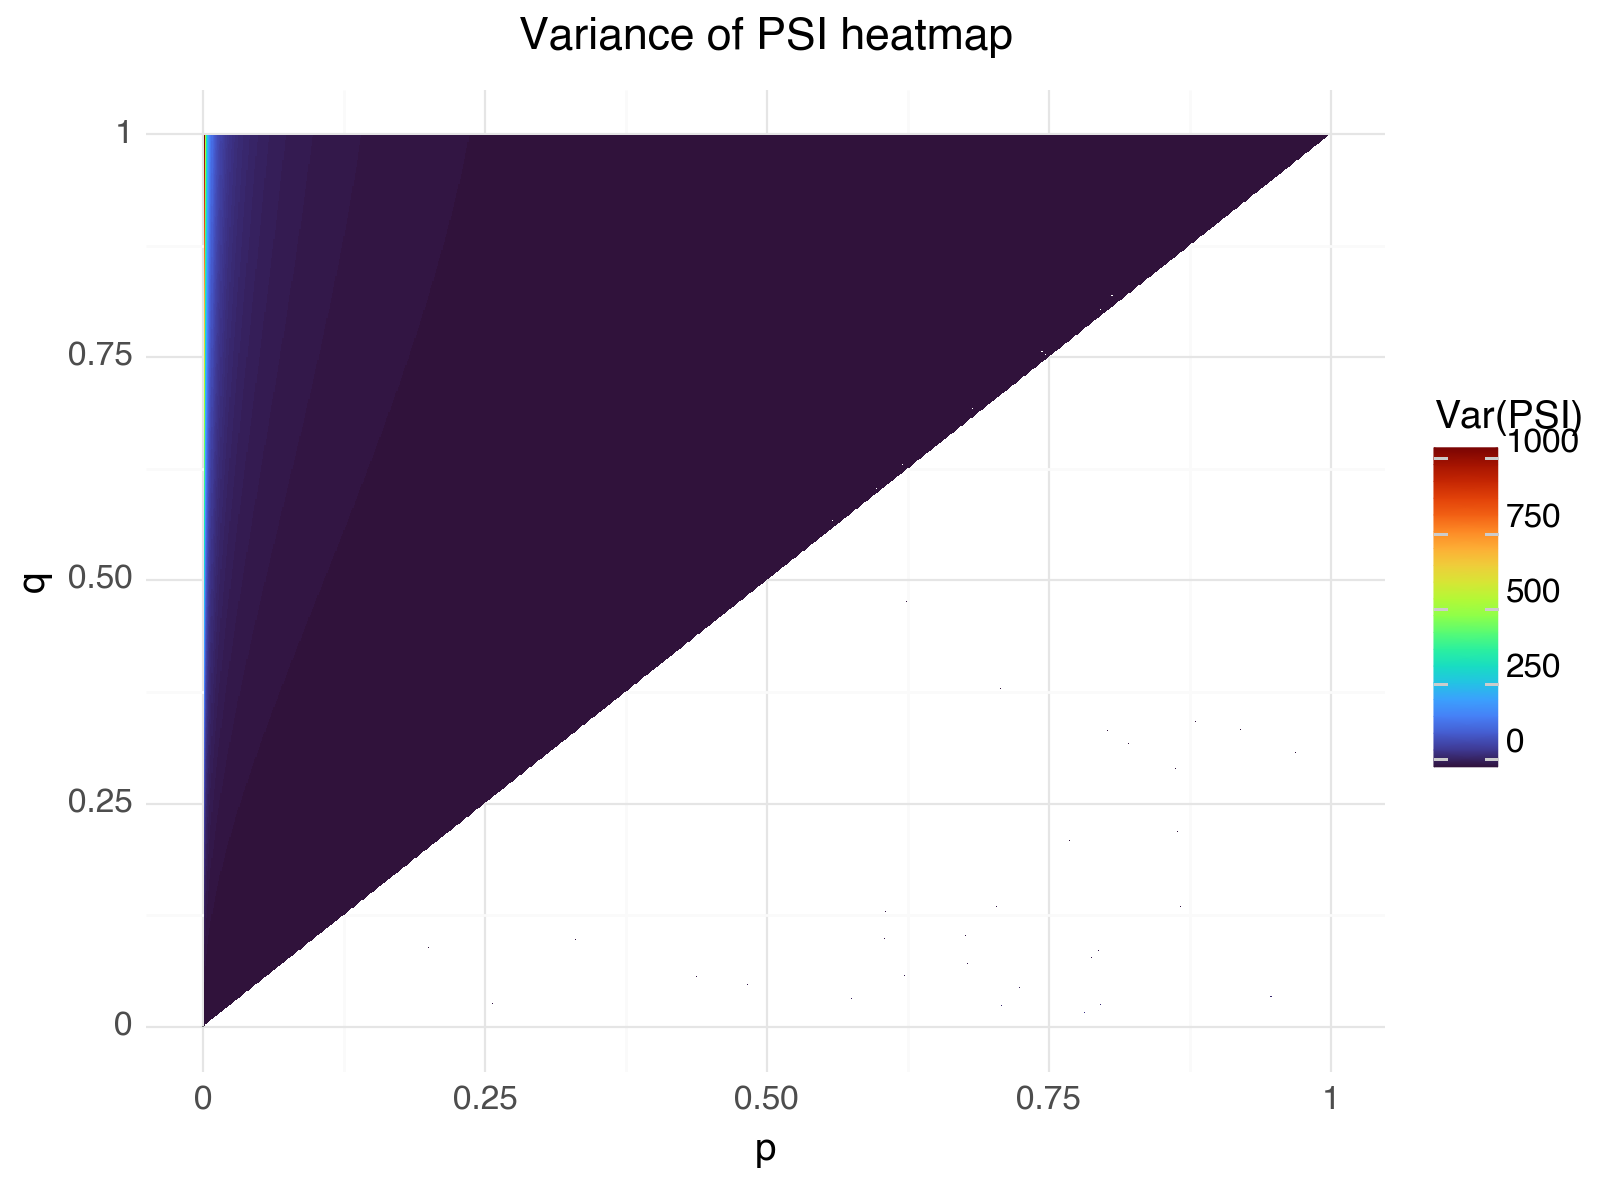

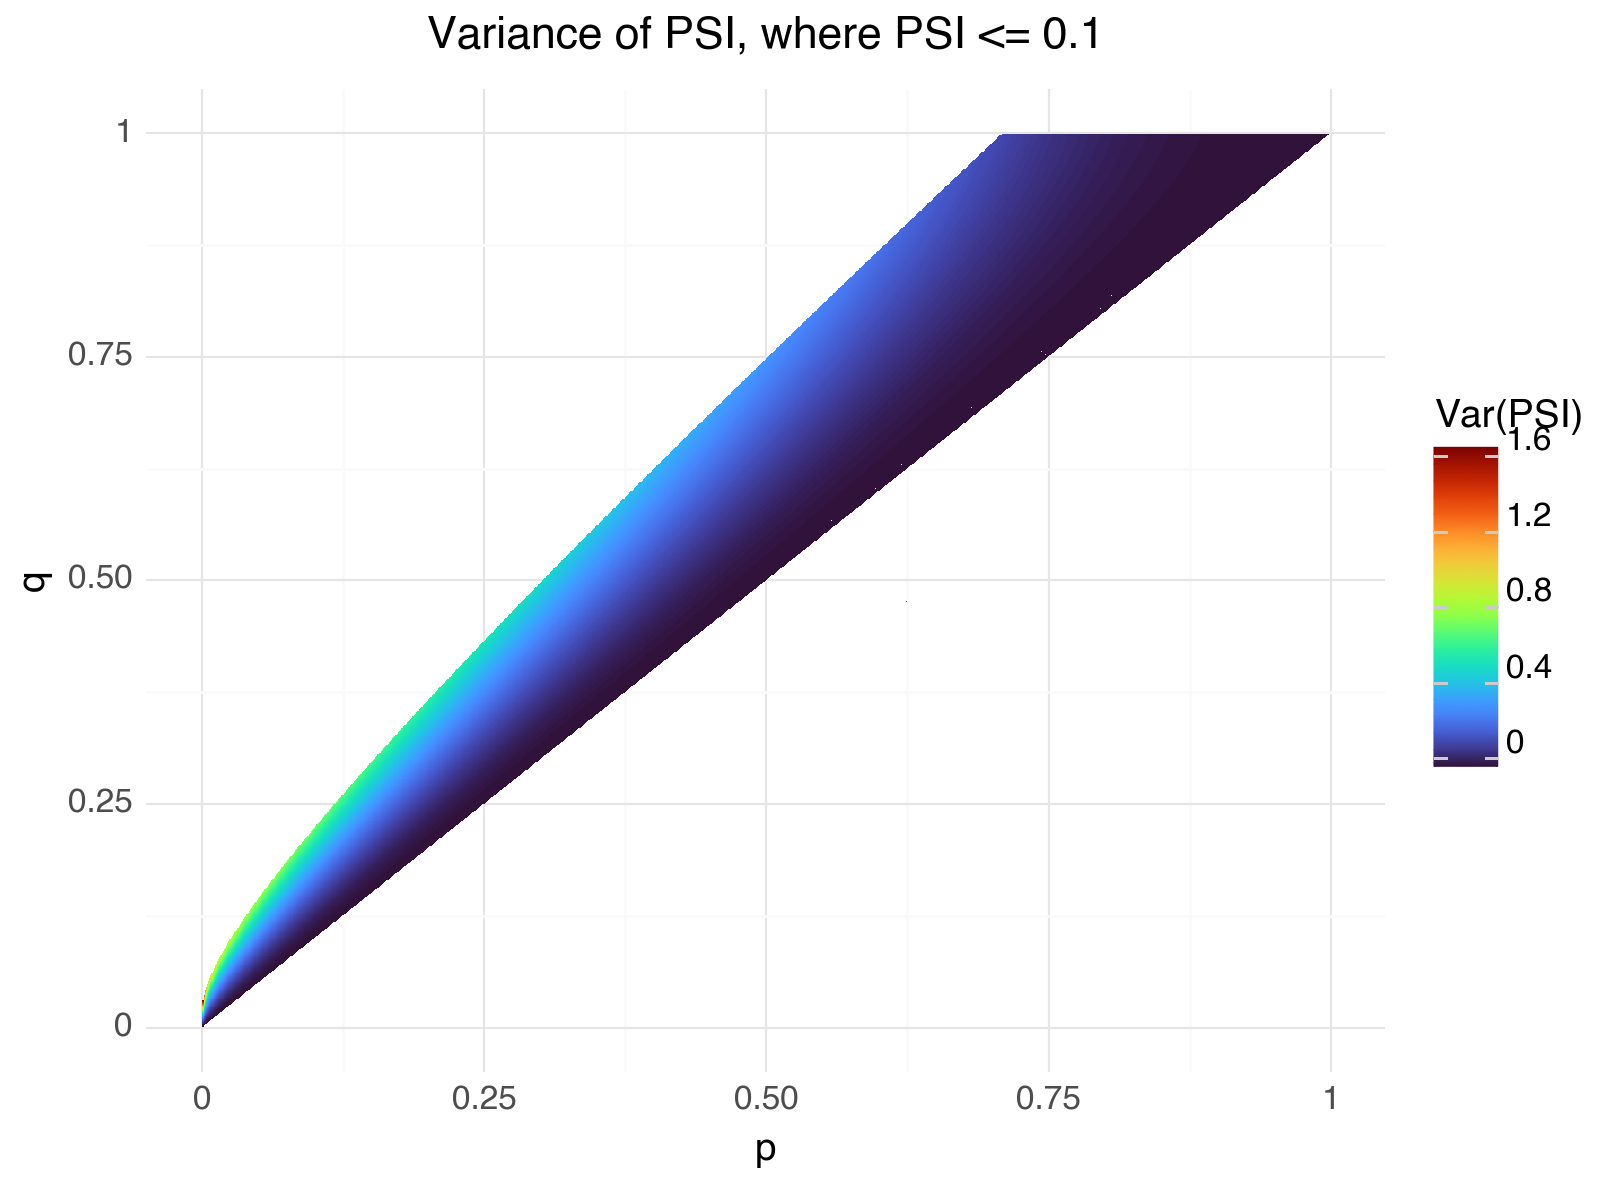

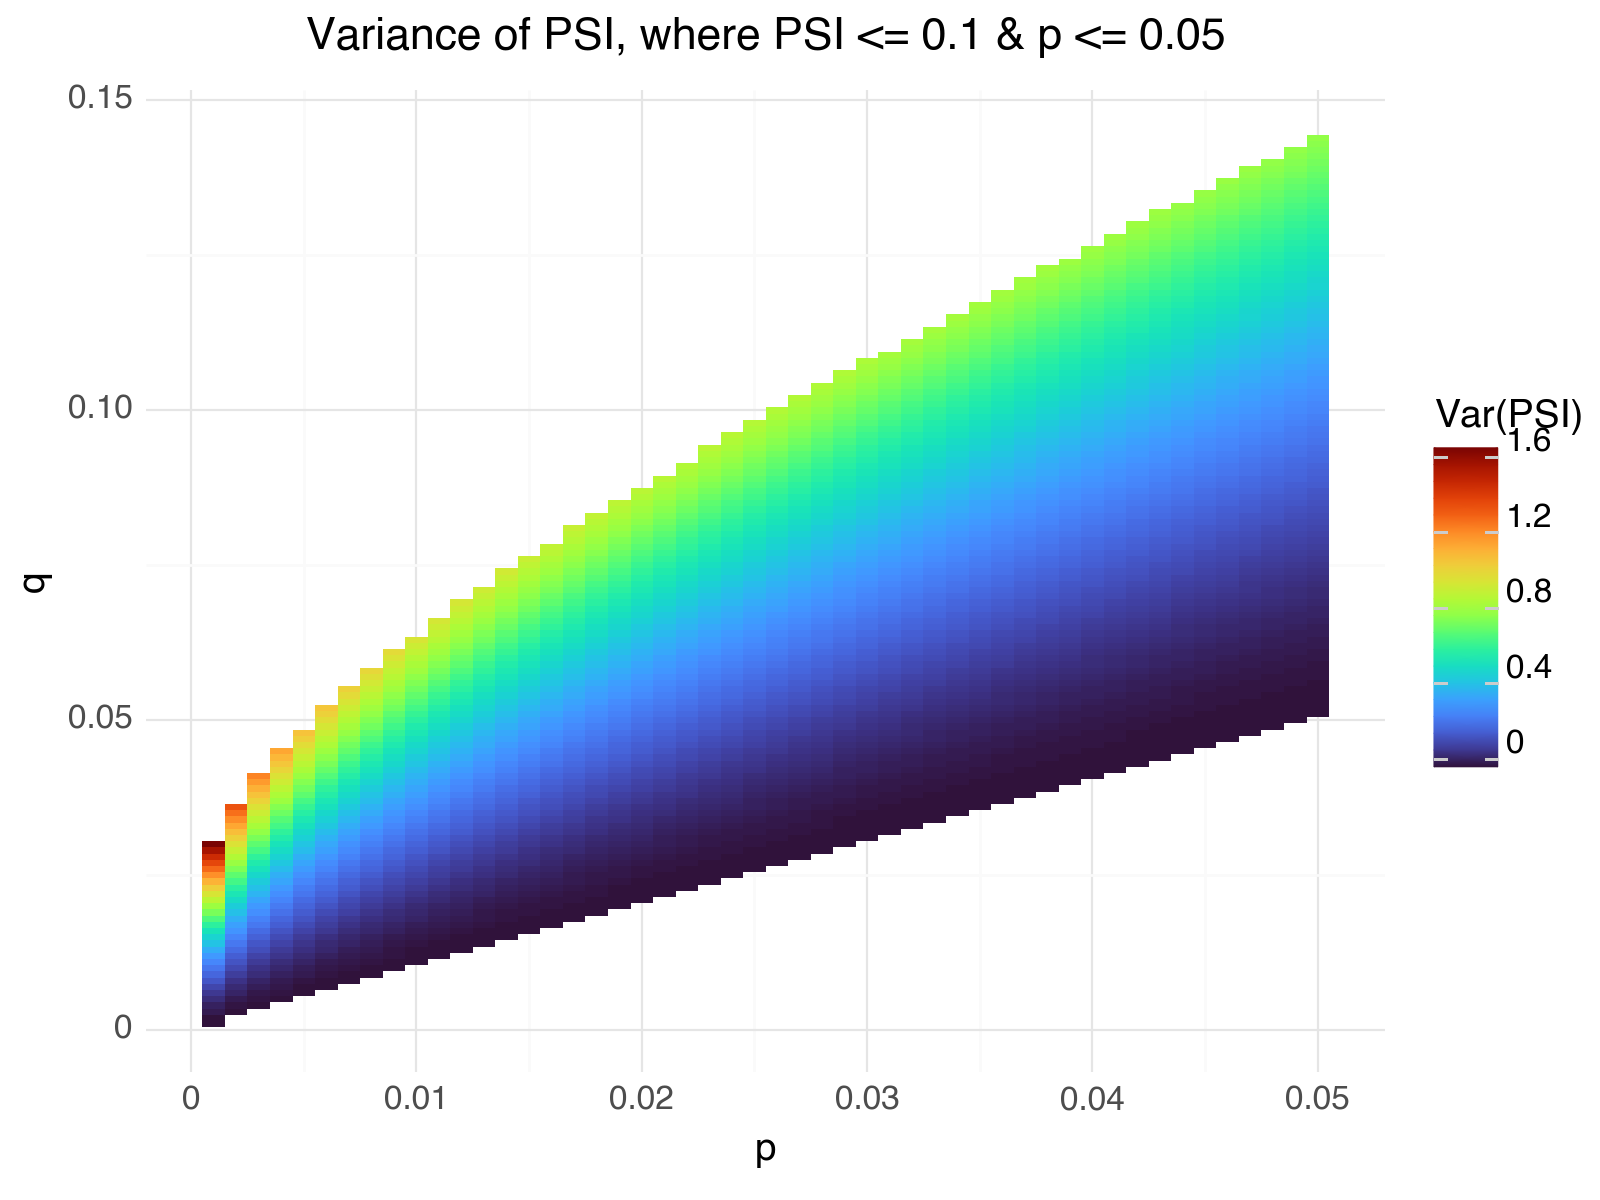

In [91]:
print(
    ggplot(seq_f, aes(x='p', y='q', fill='psi')) +
    geom_tile() +
    scale_fill_cmap('turbo') +
    theme_minimal() +
    labs(title='PSI heatmap', x='p', y='q', fill='PSI') +
    theme(figure_size=(8, 6),
          plot_title=element_text(hjust=0.5, size=16),
          axis_title=element_text(size=14),
          axis_text=element_text(size=12),
          legend_title=element_text(size=14),
          legend_text=element_text(size=12))
)

print(
    ggplot(seq_f[seq_f.psi <= 1], aes(x='p', y='q', fill='psi')) +
    geom_tile() +
    scale_fill_cmap('turbo') +
    theme_minimal() +
    labs(title='PSI <= 1', x='p', y='q', fill='PSI') +
    theme(figure_size=(8, 6),
          plot_title=element_text(hjust=0.5, size=16),
          axis_title=element_text(size=14),
          axis_text=element_text(size=12),
          legend_title=element_text(size=14),
          legend_text=element_text(size=12))
)

print(
    ggplot(seq_f[seq_f.psi <= 0.25], aes(x='p', y='q', fill='psi')) +
    geom_tile() +
    scale_fill_cmap('turbo') +
    theme_minimal() +
    labs(title='PSI <= 0.25', x='p', y='q', fill='PSI') +
    theme(figure_size=(8, 6),
          plot_title=element_text(hjust=0.5, size=16),
          axis_title=element_text(size=14),
          axis_text=element_text(size=12),
          legend_title=element_text(size=14),
          legend_text=element_text(size=12))
)

print(
    ggplot(seq_f[seq_f.psi <= 0.1], aes(x='p', y='q', fill='psi')) +
    geom_tile() +
    scale_fill_cmap('turbo') +
    theme_minimal() +
    labs(title='PSI <= 0.1', x='p', y='q', fill='PSI') +
    theme(figure_size=(8, 6),
          plot_title=element_text(hjust=0.5, size=16),
          axis_title=element_text(size=14),
          axis_text=element_text(size=12),
          legend_title=element_text(size=14),
          legend_text=element_text(size=12))
)

print(
    ggplot(seq_f, aes(x='p', y='q', fill='var')) +
    geom_tile() +
    scale_fill_cmap('turbo') +
    theme_minimal() +
    labs(title='Variance of PSI heatmap', x='p', y='q', fill='Var(PSI)') +
    theme(figure_size=(8, 6),
          plot_title=element_text(hjust=0.5, size=16),
          axis_title=element_text(size=14),
          axis_text=element_text(size=12),
          legend_title=element_text(size=14),
          legend_text=element_text(size=12))
)

print(
    ggplot(seq_f[seq_f.psi <= 0.1], aes(x='p', y='q', fill='var')) +
    geom_tile() +
    scale_fill_cmap('turbo') +
    theme_minimal() +
    labs(title='Variance of PSI, where PSI <= 0.1', x='p', y='q', fill='Var(PSI)') +
    theme(figure_size=(8, 6),
          plot_title=element_text(hjust=0.5, size=16),
          axis_title=element_text(size=14),
          axis_text=element_text(size=12),
          legend_title=element_text(size=14),
          legend_text=element_text(size=12))
)

print(
    ggplot(seq_f[(seq_f.psi <= 0.1) & (seq_f.p <= 0.05)], aes(x='p', y='q', fill='var')) +
    geom_tile() +
    scale_fill_cmap('turbo') +
    theme_minimal() +
    labs(title='Variance of PSI, where PSI <= 0.1 & p <= 0.05', x='p', y='q', fill='Var(PSI)') +
    theme(figure_size=(8, 6),
          plot_title=element_text(hjust=0.5, size=16),
          axis_title=element_text(size=14),
          axis_text=element_text(size=12),
          legend_title=element_text(size=14),
          legend_text=element_text(size=12))
)


In [52]:
seq_f[seq_f.psi <= 0.11].sort_values('var', ascending=False)

,p,q,var,psi
32001,0.001,0.032,1.795832e+00,0.107438
31001,0.001,0.031,1.698726e+00,0.103020
1030,0.030,0.001,1.603964e+00,0.098635
30001,0.001,0.030,1.603964e+00,0.098635
1029,0.029,0.001,1.511560e+00,0.094284
...,...,...,...,...
998997,0.997,0.998,2.005013e-08,0.000001
997998,0.998,0.997,2.005013e-08,0.000001
998999,0.999,0.998,1.201803e-08,0.000001
999998,0.998,0.999,1.201803e-08,0.000001
